In [1]:
# Load skincare products that have skin-type labels for KNN classification.
import pandas as pd
df = pd.read_csv("skincare_clean.csv")
labeled_df = df[df["has_skin_label"] == 1].copy()
skin_cols = ["tag_dry", "tag_oily", "tag_combination",
             "tag_normal", "tag_sensitive", "tag_acne_prone"]
print("Total Products:", len(df))
print("Labeled Products:", len(labeled_df))
print("Unlabeled Products:", len(df) - len(labeled_df))
print("\nSkin-Type Labels:")
print(labeled_df[skin_cols].sum())


Total Products: 2724
Labeled Products: 1557
Unlabeled Products: 1167

Skin-Type Labels:
tag_dry            1047.0
tag_oily            935.0
tag_combination    1209.0
tag_normal         1225.0
tag_sensitive       591.0
tag_acne_prone      397.0
dtype: float64


In [2]:
# Split labeled products into training and testing sets for KNN classification.
from sklearn.model_selection import train_test_split
X = labeled_df["ingredients_clean"]
y = labeled_df[skin_cols].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training Products:", len(X_train))
print("Testing Products:", len(X_test))


Training Products: 1245
Testing Products: 312


In [3]:
# Convert training and testing ingredient lists into numerical TF-IDF features.
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf_knn = TfidfVectorizer(token_pattern=r"[^|]+")
X_train_tfidf = tfidf_knn.fit_transform(X_train)
X_test_tfidf = tfidf_knn.transform(X_test)
print("Training Features:", X_train_tfidf.shape)
print("Testing Features:", X_test_tfidf.shape)


Training Features: (1245, 4917)
Testing Features: (312, 4917)


In [4]:
# Train the KNN classifier to predict six skin-type labels.
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_tfidf, y_train)
print("KNN Model Trained Successfully!")
print("Number of Neighbors:", knn.n_neighbors)


KNN Model Trained Successfully!
Number of Neighbors: 5


In [5]:
# Predict skin-type labels for the testing products using KNN.
y_pred = knn.predict(X_test_tfidf)
print("Total Testing Products:", len(y_pred))
print("\nFirst 5 Predicted Labels:")
print(y_pred[:5])
print("\nFirst 5 Actual Labels:")
print(y_test.iloc[:5].values)


Total Testing Products: 312

First 5 Predicted Labels:
[[1 1 1 1 1 0]
 [0 0 0 0 0 1]
 [1 0 1 1 0 0]
 [1 1 1 1 0 0]
 [1 1 1 1 0 0]]

First 5 Actual Labels:
[[1 1 1 1 1 0]
 [0 0 0 0 0 1]
 [0 1 1 1 0 1]
 [0 0 1 0 0 0]
 [1 1 1 1 1 0]]


In [6]:
# Calculate the accuracy and F1 scores of our KNN classification model.
from sklearn.metrics import accuracy_score, f1_score
accuracy = accuracy_score(y_test, y_pred)
micro_f1 = f1_score(y_test, y_pred, average="micro", zero_division=0)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
print("Exact Match Accuracy:", round(accuracy, 3))
print("Micro F1 Score:", round(micro_f1, 3))
print("Macro F1 Score:", round(macro_f1, 3))


Exact Match Accuracy: 0.272
Micro F1 Score: 0.761
Macro F1 Score: 0.715


In [7]:
# Display precision, recall, and F1 score for each skin type.
from sklearn.metrics import classification_report
print("KNN Classification Report:")
print(classification_report(  y_test, y_pred, target_names=skin_cols,zero_division=0))


KNN Classification Report:
                 precision    recall  f1-score   support

        tag_dry       0.76      0.86      0.81       201
       tag_oily       0.61      0.68      0.64       183
tag_combination       0.82      0.89      0.85       240
     tag_normal       0.79      0.92      0.85       239
  tag_sensitive       0.63      0.48      0.55       110
 tag_acne_prone       0.69      0.52      0.59        85

      micro avg       0.74      0.78      0.76      1058
      macro avg       0.72      0.72      0.72      1058
   weighted avg       0.74      0.78      0.75      1058
    samples avg       0.73      0.76      0.71      1058



In [8]:
# Create training and validation sets to find the best KNN neighbor value.
X_train_small, X_val, y_train_small, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
tfidf_val = TfidfVectorizer(token_pattern=r"[^|]+")
X_train_small_tfidf = tfidf_val.fit_transform(X_train_small)
X_val_tfidf = tfidf_val.transform(X_val)

print("Training Products:", len(X_train_small))
print("Validation Products:", len(X_val))


Training Products: 996
Validation Products: 249


In [9]:
# Test different K values and compare their validation F1 scores.
k_values = [1, 3, 5, 7, 9, 11, 15]
best_k = 1
best_score = 0
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train_small_tfidf, y_train_small)

    predictions = model.predict(X_val_tfidf)

    score = f1_score(y_val, predictions, average="macro", zero_division=0)

    print("k =", k, "Macro F1 Score =", round(score, 3))

    if score > best_score:
        best_score = score
        best_k = k

print("\nBest K:", best_k)
print("Best Validation Macro F1:", round(best_score, 3))


k = 1 Macro F1 Score = 0.68
k = 3 Macro F1 Score = 0.699
k = 5 Macro F1 Score = 0.689
k = 7 Macro F1 Score = 0.695
k = 9 Macro F1 Score = 0.702
k = 11 Macro F1 Score = 0.698
k = 15 Macro F1 Score = 0.694

Best K: 9
Best Validation Macro F1: 0.702


In [10]:
# Train KNN with the best K value and evaluate it on the testing data.
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_tfidf, y_train)
y_pred_final = knn_final.predict(X_test_tfidf)
accuracy_final = accuracy_score(y_test, y_pred_final)
micro_f1_final = f1_score(y_test, y_pred_final, average="micro", zero_division=0)
macro_f1_final = f1_score(y_test, y_pred_final, average="macro", zero_division=0)
print("Selected K:", best_k)
print("Exact Match Accuracy:", round(accuracy_final, 3))
print("Micro F1 Score:", round(micro_f1_final, 3))
print("Macro F1 Score:", round(macro_f1_final, 3))


Selected K: 9
Exact Match Accuracy: 0.282
Micro F1 Score: 0.772
Macro F1 Score: 0.712


In [11]:
# Display the final KNN classification report for all six skin types.
print("Final KNN Classification Report (k = 9):")

print(classification_report( y_test,y_pred_final, target_names=skin_cols, zero_division=0))


Final KNN Classification Report (k = 9):
                 precision    recall  f1-score   support

        tag_dry       0.76      0.88      0.81       201
       tag_oily       0.66      0.74      0.70       183
tag_combination       0.81      0.92      0.86       240
     tag_normal       0.78      0.95      0.86       239
  tag_sensitive       0.67      0.46      0.55       110
 tag_acne_prone       0.64      0.40      0.49        85

      micro avg       0.75      0.80      0.77      1058
      macro avg       0.72      0.73      0.71      1058
   weighted avg       0.74      0.80      0.76      1058
    samples avg       0.75      0.77      0.72      1058



In [12]:
# Display confusion matrices for sensitive and acne-prone skin predictions.
from sklearn.metrics import confusion_matrix
for skin in ["tag_sensitive", "tag_acne_prone"]:
    i = skin_cols.index(skin)

    cm = confusion_matrix(y_test.iloc[:, i],y_pred_final[:, i], labels=[0, 1])
    print("\n", skin)

    display(pd.DataFrame(cm,index=["Actual 0", "Actual 1"],columns=["Predicted 0", "Predicted 1"]))



 tag_sensitive


,Predicted 0,Predicted 1
Actual 0,177,25
Actual 1,59,51



 tag_acne_prone


,Predicted 0,Predicted 1
Actual 0,208,19
Actual 1,51,34


In [13]:
# Compare KNN with a simple baseline using the most common training labels.
baseline_pred = pd.DataFrame(index=y_test.index)
for skin in skin_cols:
    baseline_pred[skin] = y_train[skin].mode()[0]
print("Baseline Exact Match Accuracy:",
      round(accuracy_score(y_test, baseline_pred), 3))
print("Baseline Micro F1:",
      round(f1_score(y_test, baseline_pred, average="micro", zero_division=0), 3))
print("Baseline Macro F1:",
      round(f1_score(y_test, baseline_pred, average="macro", zero_division=0), 3))
print("\nKNN Macro F1:", round(macro_f1_final, 3))


Baseline Exact Match Accuracy: 0.067
Baseline Micro F1: 0.748
Baseline Macro F1: 0.543

KNN Macro F1: 0.712


In [14]:
# Train KNN on all labeled products and save the final model and TF-IDF vectorizer.
import joblib

tfidf_final = TfidfVectorizer(token_pattern=r"[^|]+")

X_all = tfidf_final.fit_transform(labeled_df["ingredients_clean"])

y_all = labeled_df[skin_cols].astype(int)

knn_deploy = KNeighborsClassifier(n_neighbors=best_k)

knn_deploy.fit(X_all, y_all)

joblib.dump(knn_deploy, "knn_skinmatch.pkl")
joblib.dump(tfidf_final, "tfidf_knn.pkl")

print("Final KNN Model Saved Successfully!")
print("TF-IDF Vectorizer Saved Successfully!")
print("Training Products:", len(labeled_df))
print("Selected K:", best_k)


Final KNN Model Saved Successfully!
TF-IDF Vectorizer Saved Successfully!
Training Products: 1557
Selected K: 9


In [15]:
# Predict skin-type labels for products that do not have existing labels.
unlabeled_df = df[df["has_skin_label"] == 0].copy()

X_unlabeled = tfidf_final.transform(unlabeled_df["ingredients_clean"])

predictions = knn_deploy.predict(X_unlabeled)

pred_cols = ["pred_" + skin for skin in skin_cols]

unlabeled_df[pred_cols] = predictions

print("Total Unlabeled Products:", len(unlabeled_df))
print("\nPredicted Skin-Type Counts:")
print(unlabeled_df[pred_cols].sum())

print("\nFirst 5 Products with Predictions:")
display(unlabeled_df[["brand", "name"] + pred_cols].head())


Total Unlabeled Products: 1167

Predicted Skin-Type Counts:
pred_tag_dry             921
pred_tag_oily            761
pred_tag_combination    1086
pred_tag_normal         1110
pred_tag_sensitive       231
pred_tag_acne_prone      113
dtype: int64

First 5 Products with Predictions:


,brand,name,pred_tag_dry,pred_tag_oily,pred_tag_combination,pred_tag_normal,pred_tag_sensitive,pred_tag_acne_prone
41,CeraVe,SA Cleanser Bar for Rough & Bumpy Skin,1,0,0,1,0,0
48,CeraVe,SA Cream for Rough & Bumpy Skin,1,0,0,1,0,0
63,CeraVe,SA Body Wash for Rough & Bumpy Skin,0,0,0,1,0,0
76,CeraVe,SA Lotion for Rough & Bumpy Skin,1,0,0,1,0,0
97,Algenist,Triple Algae Eye Renewal Balm Eye Cream,1,1,1,1,0,0


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

lr_predictions = pd.DataFrame(index=y_test.index)
lr_models = {}

for skin in skin_cols:
    model = LogisticRegression(max_iter=1000, random_state=42)

    model.fit(X_train_tfidf, y_train[skin])

    lr_predictions[skin] = model.predict(X_test_tfidf)

    lr_models[skin] = model

    print(skin, "model trained successfully!")

print("\nLogistic Regression Results:")

print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("Micro F1:", f1_score(y_test, lr_predictions, average="micro"))
print("Macro F1:", f1_score(y_test, lr_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=skin_cols,
    zero_division=0
))


tag_dry model trained successfully!
tag_oily model trained successfully!
tag_combination model trained successfully!
tag_normal model trained successfully!
tag_sensitive model trained successfully!
tag_acne_prone model trained successfully!

Logistic Regression Results:
Accuracy: 0.21153846153846154
Micro F1: 0.7754199823165341
Macro F1: 0.6856089228574276

Classification Report:
                 precision    recall  f1-score   support

        tag_dry       0.72      0.94      0.81       201
       tag_oily       0.62      0.87      0.73       183
tag_combination       0.78      0.98      0.87       240
     tag_normal       0.77      0.99      0.87       239
  tag_sensitive       0.74      0.34      0.46       110
 tag_acne_prone       0.84      0.25      0.38        85

      micro avg       0.73      0.83      0.78      1058
      macro avg       0.74      0.73      0.69      1058
   weighted avg       0.74      0.83      0.75      1058
    samples avg       0.72      0.79      0.7

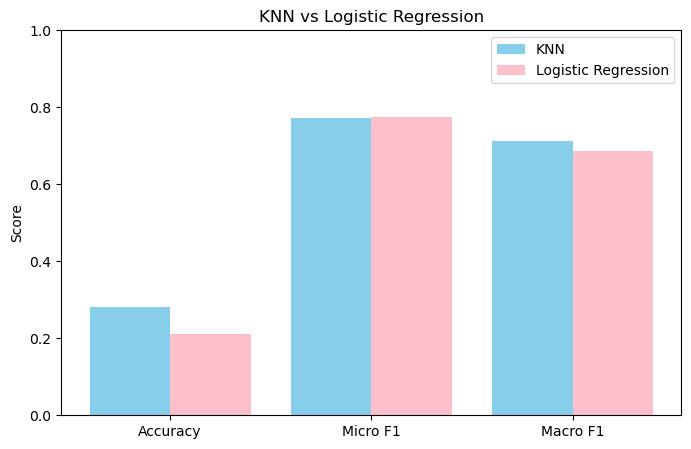

In [22]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Micro F1", "Macro F1"]

# Earlier KNN test results
knn_scores = [accuracy_final,micro_f1_final, macro_f1_final]

lr_scores = [
    accuracy_score(y_test, lr_predictions),
    f1_score(y_test, lr_predictions, average="micro"),
    f1_score(y_test, lr_predictions, average="macro")
]

x = range(len(metrics))

plt.figure(figsize=(8, 5))

plt.bar([i - 0.2 for i in x], knn_scores,
        width=0.4, label="KNN", color="skyblue")

plt.bar([i + 0.2 for i in x], lr_scores,
        width=0.4, label="Logistic Regression", color="pink")

plt.xticks(list(x), metrics)
plt.ylabel("Score")
plt.title("KNN vs Logistic Regression")
plt.ylim(0, 1)
plt.legend()
plt.show()


In [19]:
import pandas as pd
import joblib
from sklearn.linear_model import LogisticRegression

# Load the original cleaned dataset
data = pd.read_csv("skincare_clean.csv")

# Select products with known skin-type labels
labeled = data[data["has_skin_label"] == 1].copy()

# Load the TF-IDF vectorizer trained on all labeled products
vectorizer = joblib.load("tfidf_knn.pkl")

# Prepare ingredient features
X_full = vectorizer.transform(
    labeled["ingredients_clean"].fillna("")
)

# Train six Logistic Regression models
lr_final_models = {}

for skin in skin_cols:
    model = LogisticRegression(max_iter=1000, random_state=42)

    model.fit(X_full, labeled[skin].astype(int))

    lr_final_models[skin] = model

    print(skin, "saved model trained!")

# Save all six models in one file
joblib.dump(lr_final_models, "logistic_regression.pkl")

print("\nLogistic Regression saved successfully!")


tag_dry saved model trained!
tag_oily saved model trained!
tag_combination saved model trained!
tag_normal saved model trained!
tag_sensitive saved model trained!
tag_acne_prone saved model trained!

Logistic Regression saved successfully!


In [20]:
import joblib
import pandas as pd

# Load saved models and vectorizer
saved_models = joblib.load("logistic_regression.pkl")
saved_vectorizer = joblib.load("tfidf_knn.pkl")

# Select 3 products for testing
sample = pd.read_csv("skincare_clean.csv").head(3)

# Convert ingredients into TF-IDF features
X_sample = saved_vectorizer.transform(
    sample["ingredients_clean"].fillna("")
)

# Predict all six skin-type labels
predictions = pd.DataFrame()

for skin in skin_cols:
    predictions[skin] = saved_models[skin].predict(X_sample)

# Display results
predictions.insert(0, "Product", sample["name"].values)

print("Logistic Regression loaded successfully!")
display(predictions)


Logistic Regression loaded successfully!


,Product,tag_dry,tag_oily,tag_combination,tag_normal,tag_sensitive,tag_acne_prone
0,Balancing & Clarifying Serum,1,1,1,1,1,0
1,GF 15% Solution,1,1,1,1,1,0
2,Multi-Antioxidant Radiance Serum,1,1,1,1,1,0


In [21]:
# Save all skincare products with separate KNN predictions for unlabeled products.
df_with_predictions = df.copy()
for col in pred_cols:
    df_with_predictions[col] = pd.NA

df_with_predictions.loc[unlabeled_df.index, pred_cols] = unlabeled_df[pred_cols]

df_with_predictions.to_csv("skincare_with_predictions.csv", index=False)

print("Dataset with KNN predictions saved successfully!")
print("Total Products:", len(df_with_predictions))
print("Original Labeled Products:", len(labeled_df))
print("Products with KNN Predictions:", len(unlabeled_df))


Dataset with KNN predictions saved successfully!
Total Products: 2724
Original Labeled Products: 1557
Products with KNN Predictions: 1167



### Conclusion

In this phase, KNN and Logistic Regression were used to predict six skin-type labels based on skincare ingredients.

The dataset contained 1,557 labeled products and 1,167 unlabeled products. TF-IDF was used to convert ingredient lists into numerical features.

For KNN, different neighbor values were tested using a validation set. The best value was k = 9.

Both algorithms were evaluated on the same testing dataset.

| Metric | KNN | Logistic Regression |
|---|---|---|
| Exact Match Accuracy | 0.282 | 0.212 |
| Micro F1 | 0.772 | 0.775 |
| Macro F1 | 0.712 | 0.686 |

KNN achieved better exact-match accuracy and Macro F1, while Logistic Regression achieved a slightly higher Micro F1.

Both models performed less effectively for sensitive and acne-prone skin labels.

KNN was selected as the primary classification model. It was retrained on all labeled products and used to predict skin-type labels for 1,167 unlabeled products.

Six Logistic Regression classifiers were also trained on all labeled products and saved in `logistic_regression.pkl` for future use.

Both algorithms were successfully implemented and compared. Their predictions represent patterns in the dataset rather than medically verified product suitability.
